## From Words to Numbers, Models and Time Series
For all concepts we will use a small corpus: **Alice in Wonderland** from NLTK, with each sentence treated as a document.

In [1]:
#imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import re
import string
from collections import Counter

import nltk

In [2]:
from nltk.corpus import gutenberg, stopwords
from nltk.stem import WordNetLemmatizer

In [3]:
alice_raw = [" ".join(s) for s in gutenberg.sents('carroll-alice.txt')]

print(alice_raw[:2])

alice_raw = [s for s in alice_raw if len(s.split()) >= 4]

print(alice_raw[:2])

["[ Alice ' s Adventures in Wonderland by Lewis Carroll 1865 ]", 'CHAPTER I .']
["[ Alice ' s Adventures in Wonderland by Lewis Carroll 1865 ]", 'Down the Rabbit - Hole']


Yesterday's pipeline, packed into one function, **lowercase, removal of irrelevant characters, removal of stop words, tokenize, lemmatize**. We will reuse it all today.

In [4]:
#stopwords
#lemmatization
#create two functions for both lemmatization and preprocessing

stop_words = set(stopwords.words('english')) - {'not', 'nor', 'no'}
lemmatizer = WordNetLemmatizer()


def lemma(word):
    return lemmatizer.lemmatize(word)

def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = text.split()
    return " ".join(lemma(t) for t in tokens if t not in stop_words and len(t) > 2)



In [ ]:
#load Alice in Wonderland, one document per sentence
#preprocess it and check results
alice_clean = [preprocess(s) for s in alice_raw]

print(alice_clean[5])
print(alice_raw[5])

shall late
I shall be late !'


In [6]:

print(alice_clean[4])
print(alice_raw[4])

nothing remarkable nor alice think much way hear rabbit say dear
There was nothing so VERY remarkable in that ; nor did Alice think it so VERY much out of the way to hear the Rabbit say to itself , ' Oh dear !


## Vectorization and Bag of Words(BoW)
**Vectorization** is the act of turning text into a list of numbers, **vectors**, for the computer to compare, count and learn from it.

**Bag of Words** is the simplest vectorization: build a vocabulary of every distinct word, then describe each document by how many times each vocatulary word appears in it. Order is thrown away, like tipping all the words in a gunia

In [8]:
#by hand example
s1 = "Most inventive plot since Rosemary's Baby."
s2 = "Spanning continents and inpired by true events, what follows is one of Levin's most masterful tales."
s3 = "Levin is the Swiss watchmaker of the suspense novel."

sentences = [s1, s2, s3]

print(sentences)

["Most inventive plot since Rosemary's Baby.", "Spanning continents and inpired by true events, what follows is one of Levin's most masterful tales.", 'Levin is the Swiss watchmaker of the suspense novel.']


In [9]:
#preprocess the sentences
cleaned_sentences = [None]

tokens = [s.split() for s in sentences]

vocab = sorted(set(w for s in tokens for w in s))
print('\n Vocabulary:', vocab)


 Vocabulary: ['Baby.', 'Levin', "Levin's", 'Most', "Rosemary's", 'Spanning', 'Swiss', 'and', 'by', 'continents', 'events,', 'follows', 'inpired', 'inventive', 'is', 'masterful', 'most', 'novel.', 'of', 'one', 'plot', 'since', 'suspense', 'tales.', 'the', 'true', 'watchmaker', 'what']


In [10]:
len(vocab)

28

In [11]:
vocab

['Baby.',
 'Levin',
 "Levin's",
 'Most',
 "Rosemary's",
 'Spanning',
 'Swiss',
 'and',
 'by',
 'continents',
 'events,',
 'follows',
 'inpired',
 'inventive',
 'is',
 'masterful',
 'most',
 'novel.',
 'of',
 'one',
 'plot',
 'since',
 'suspense',
 'tales.',
 'the',
 'true',
 'watchmaker',
 'what']

In [16]:
#by hand on three sentences from the corpus

vectors = [[doc.count(w) for w in vocab] for doc in tokens]

pd.DataFrame(vectors, columns=vocab, index=['s1', 's2', 's3'])



,Baby.,Levin,Levin's,Most,Rosemary's,Spanning,Swiss,and,by,continents,...,of,one,plot,since,suspense,tales.,the,true,watchmaker,what
s1,1,0,0,1,1,0,0,0,0,0,...,0,0,1,1,0,0,0,0,0,0
s2,0,0,1,0,0,1,0,1,1,1,...,1,1,0,0,0,1,0,1,0,1
s3,0,1,0,0,0,0,1,0,0,0,...,1,0,0,0,1,0,2,0,1,0


In [ ]:
a = 'This is Nairobi'
b = 'This is Westlands located in Nairobi'
c = 'This is Malindi'


# tokens_a_b_c = ['This', 'is', 'Nairobi','This', 'is', 'Westlands', 'located', 'in','Nairobi', 'This','is', 'Malindi']

sents = [a,b,c]
tokens_a_b_c = [s.split() for s in sents]

vocabulary = sorted(set(w for s in tokens_a_b_c for w in s))

vocabulary

vectors = [[doc.count(w) for w in vocabulary] for doc in tokens_a_b_c]

pd.DataFrame(vectors, columns=vocabulary, index=['a', 'b', 'c'])

# """ 

# vocabulary =  This, is, Nairobi, Westlands, located, in, Malindi

# a_vector = 1   1   1   0   0   0   0
# b_vector = 1   1   1   1   1   1   0
# c_vector = 1   1   0   0   0   0   1
# """


,Malindi,Nairobi,This,Westlands,in,is,located
a,0,1,1,0,0,1,0
b,0,1,1,1,1,1,1
c,1,0,1,0,0,1,0


#### **CountVectorizer** on the whole book

In [20]:
#use sklearn's countvectorizer
from sklearn.feature_extraction.text import CountVectorizer


bow = CountVectorizer()
X_bow = bow.fit_transform(alice_clean)

X_bow.shape

(1598, 2213)

In [23]:
1 - X_bow.nnz /np.prod(X_bow.shape)

np.float64(0.9966734287719569)

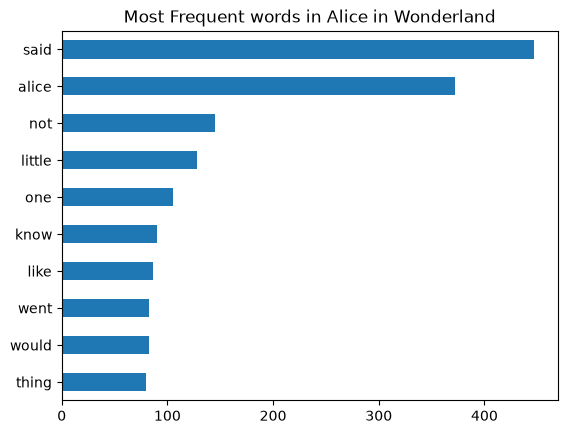

In [25]:
counts = np.asarray(X_bow.sum(axis=0)).ravel()
top = pd.Series(counts, index=bow.get_feature_names_out()).sort_values(ascending=False).head(10)
top.sort_values().plot.barh(title='Most Frequent words in Alice in Wonderland')
plt.show()

## N-grams
Bag of Words treats **white** and **rabbit** as unrelated, however "**white rabbit**" is one character in the book. An **n-gram** is a sequence of n consecutive words:
- Unigram
- bigram
- trigram

Bigrams helps us reveal the characters example: `mock turtle`, `march hare`, `white rabbit`. Single words could never show that. 

However, it comes with a catch; longer n-grams capture more context but make the vocabulary explode. More vocabulary means more columns, more columns mean more memory and more sparsity, and many n-grams appear only once. In practice we **(1, 2)** and filter rare terms with **min_df**.

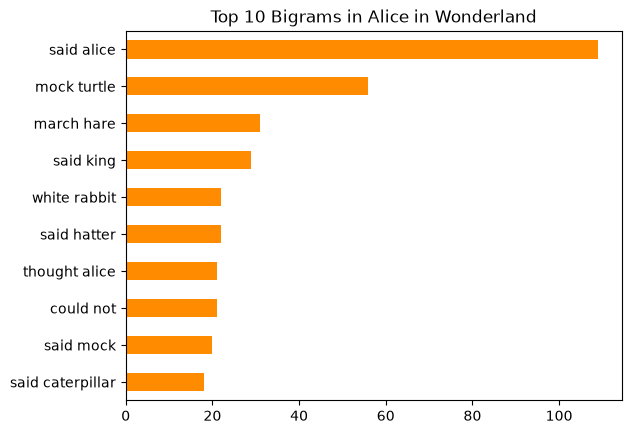

In [29]:
bigram_vec = CountVectorizer(ngram_range=(2,2))
X_bi = bigram_vec.fit_transform(alice_clean)

bi_counts = pd.Series(np.asarray(X_bi.sum(axis=0)).ravel(), index=bigram_vec.get_feature_names_out()).sort_values(ascending=False)

bi_counts.head(10).sort_values().plot.barh(color = 'darkorange', title='Top 10 Bigrams in Alice in Wonderland')
plt.show()

## TF-IDF
**Problem:** BoW rewards words that are *common*. We want words that are *distinctive*.

$$\text{TF-IDF}(t, d) = \text{TF}(t, d) \times \text{IDF}(t), \qquad \text{IDF}(t) = \ln\frac{N}{df(t)}$$

- **TF**: how often word *t* appears in document *d*
- **IDF**: how rare *t* is across all *N* documents (*df* = number of documents containing it)

A word that appears everywhere gets IDF near zero. A word that appears in few documents gets a large IDF.

In [33]:
#example 1 with custom functions
import math


tiny = ['the rabbit is late', 'the queen is angry', 'the rabbit is brilliant', 'the white rabbit killed the turtle']
tiny_tokens = [d.split() for d in tiny]

N = len(tiny)

def idf(term):
    return math.log(N / sum(term in d for d in tiny_tokens))

for term in ['the', 'rabbit', 'queen']:
    print(f"{term:8s} idf = {idf(term):.3f}")

the      idf = 0.000
rabbit   idf = 0.288
queen    idf = 1.386


### TF-IDF on Alice
When doing this for a corpus like Alice in Wonderland, we answer the question: **What is each part of the book about?**

Let's split the book into `12` equal chunks(roughly resembling chapters) and treat each chunk as one document. 

Then for each chunk we compare the top **BoW** words with the top **TF-IDF** words.

In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer

#instantiation
tv_chunks = TfidfVectorizer(max_df=0.7)

chunks = np.array_split(np.array(alice_clean, dtype=object), 12)
chunks_docs = [' '.join(c) for c in chunks]

cv_chunks = CountVectorizer()
M_count = cv_chunks.fit_transform(chunks_docs)

M_tfidf = tv_chunks.fit_transform(chunks_docs)



In [36]:
def top_terms(matrix, vec, i, n=4):
    row = matrix[i].toarray().ravel()
    return ', '.join(vec.get_feature_names_out()[row.argsort()[::-1][:n]])


pd.DataFrame({
    'chunk':range(1, 13),
    'top BoW words': [top_terms(M_count, cv_chunks, i) for i in range(12)],
    'top TF-IDF words': [top_terms(M_tfidf, tv_chunks, i) for i in range(12)],
}).set_index('chunk')

,top BoW words,top TF-IDF words
chunk,,
1,"alice, little, not, way","key, hall, bat, door"
2,"said, mouse, alice, not","mouse, dodo, race, prize"
3,"alice, said, little, rabbit","mouse, window, glove, dinah"
4,"said, alice, caterpillar, little","caterpillar, puppy, bill, youth"
5,"alice, said, little, footman","footman, pigeon, serpent, baby"
6,"said, alice, hatter, cat","hatter, march, cat, hare"
7,"said, alice, dormouse, hatter","dormouse, hatter, twinkle, march"
8,"said, alice, queen, head","queen, hedgehog, flamingo, king"
9,"said, alice, turtle, mock","turtle, mock, gryphon, queen"


Comparing the two columns, what does BoW give and what does TF-IDF bring?

## BM25
TF-IDF is great for features, however, for **search ranking**, most engines(Lucene, ElasticSearch) use BM25 since it improves on TF-IDF.

It does this in two ways:
- **Saturation**: the 10th occurrence of a word should not count 10 times the first.
- **Length normalization**: a long document should not win just because it is long.

$$\text{BM25}(q, d) = \sum_{t \in q} \text{IDF}(t) \cdot \frac{f(t,d)\,(k_1 + 1)}{f(t,d) + k_1\,(1 - b + b\,\frac{|d|}{\text{avgdl}})}$$

$k_1$ controls saturation (typically 1.2-2). $b$ controls length normalisation (0 = ignore length, 1 = full).

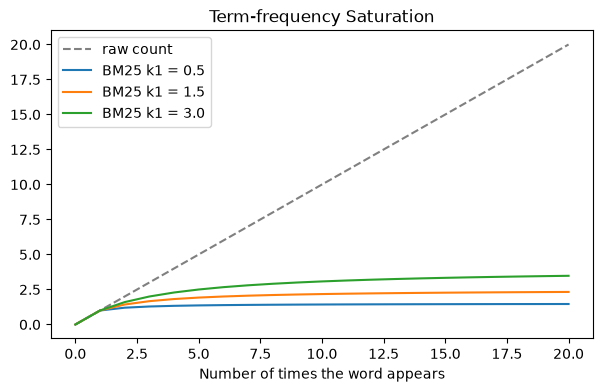

In [38]:
#visualization for seeing saturation
f = np.arange(0, 21)
plt.figure(figsize=(7,4))
plt.plot(f, f, '--', color='gray', label='raw count')

for k1 in [0.5, 1.5, 3.0]:
    plt.plot(f, f * (k1 + 1)/(f + k1), label=f'BM25 k1 = {k1}')
plt.legend()
plt.title('Term-frequency Saturation')
plt.xlabel('Number of times the word appears')
plt.show()

In [16]:
#bm25 searching alice

In [17]:
#compare bm25 and tf-idf(cosine similarity)

### Conclusion
So far we ran most steps by hand. Now we will put everything in an elegant **pipeline**.

Our task: **Author Identification** Given one sentence, which book is it from? We use sentences from three NLTK Gutenberg books: 
- `Alice in Wonderland` by **Carroll** 
- `Emma` by **Austen** 
- `Moby Dick` by **Melville**


Before we do this; 
## Why do we use one Pipeline?
1. 
2. 

## Model Assessment
One accuracy number is not enough. We need to ask:
- **Where does it fail?**
- **How stable is the score?**
- **What did it learn?**

In [ ]:
#Where does it fail

In [18]:
#Is the score stable? Cross-validation

In [19]:
#What did the model learn?

## Introduction to Time Series Analysis
Everything so far treated each document as independent. Many real datasets are **ordered in time**: daily sales, M-Pesa transactions, web traffic, tweets per day. A **time series** is a sequence of observations taken at regular time intervals.

**Why is it different?**
- Order matters: tomorrow depends on today
- We **cannot shuffle** the data for train/test splits. We train on the past and test on the future.
- We look for **components**:
  - **Trend:** the long-run direction
  - **Seasonality:** repeating patterns (weekly, yearly)
  - **Noise:** random variation